# Can a different model beat the paper's LightGBM?

`notebook.ipynb` reproduced Zoabi et al. (2021), and `alternative-data.ipynb` took the paper's approach to the US and Brazil. Both kept the paper's model, LightGBM, fixed. This notebook asks the opposite question: **keeping the data fixed, can a different machine-learning technique, model type or approach do better?** It starts with the paper's Israeli data, then checks whether anything that wins there also generalises to the other countries.

Hyperparameter tuning of the paper's LightGBM is out of scope: a groupmate has already done that ([warren-davies4/covid-prediction-hackathon](https://github.com/warren-davies4/covid-prediction-hackathon)). Their tuned model is used here as the benchmark to beat.

**Contents**
1. **Goal and rules**: what counts as "outperform", and how we avoid fooling ourselves
2. **Benchmarks**: the paper's LightGBM and the groupmate's tuned model
3. **How much headroom is there?** The best score any model could possibly reach
4. **The model zoo**: 15 techniques on the Israeli data
5. **Approaches beyond model type**: recency weighting, ensembles, extra training data
6. **Bias check**: do the gains survive without the biased symptoms, and without contact?
7. **All three countries**: each on its own, pooled, and on a country the model has never seen
8. **Head-to-head with the tuned model** on its own split
9. **Summary, presentation assets and takeaways**

In [1]:
%load_ext autoreload
%autoreload 2

import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

import symptompred as sp

pd.set_option("display.max_columns", None)
BLUE, ORANGE, AQUA, GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#e34948"
COLORS = {"israel": BLUE, "carbon_health": ORANGE, "brazil": AQUA}   # one colour per dataset, as in alternative-data
FAMILY_COLORS = {"boosting (benchmark)": "#0b0b0b", "boosting": BLUE, "linear": ORANGE, "lookup": AQUA,
                 "neural": "#6250d6", "bagging": "#eda100", "tree": "#e87ba4", "probabilistic": "#008300"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

---
# 1. Goal and rules

**Outperform** means all three of:
1. **Higher auROC *and* higher auPRC** on the test week than the benchmark.
2. **Reliably higher**: a *paired* bootstrap 95% confidence interval for the difference that excludes 0. `sp.paired_bootstrap` resamples the same test rows for both models, so test-set noise they share cancels out. That makes it much more sensitive than comparing two separate confidence intervals.
3. **Not a product of reporting bias.** The gain must survive without the three "biased" symptoms (sore throat, shortness of breath, headache), which were recorded far more often for people who tested positive. Part of the tuned model's gain came from leaning harder on these.

**Avoiding fooling ourselves**
- Every choice (which models to carry forward, hyperparameter grids, ensemble members) is made by **5-fold cross-validation on the training window only** (`sp.cross_validate`, `sp.select_and_score`). `select_and_score` refuses to run if the training data overlaps the test period.
- The test week is used once, to score the final models, as in the groupmate's protocol.
- Every technique uses **light, standard defaults** (see `sp.registry()` in `symptompred/alternatives.py`). The question is which *technique* works, not how far each can be tuned.

## 1.1 New library tools

All model code lives in `symptompred`, so every experiment below (and `sp.compare` / `sp.leave_one_out` from `alternative-data`) can run any technique:

| Tool | What it does |
|---|---|
| `sp.EstimatorModel(estimator, ...)` | wraps any scikit-learn-style classifier with the same feature, missing-value and pooling handling as `SymptomModel` |
| `sp.registry()` | name → factory for all 15 techniques, so each is defined once |
| `sp.CellRateClassifier` | a lookup table: the positive rate for each exact combination of answers, shrunk towards logistic regression for rare combinations |
| `sp.ScorecardClassifier` | logistic regression rounded to integer points, like a clinical risk score |
| `sp.EnsembleModel(members, method)` | averages or stacks several models |
| `source_feature=True` | adds a 0/1 column per country, so a pooled model can learn country-specific adjustments |
| `sp.paired_bootstrap(y, p_a, p_b)` | is A reliably better than B on the same rows? |
| `sp.oracle_ceiling(df, features)` | the best score *any* model could reach with these features |
| `sp.cross_validate`, `sp.select_and_score` | model selection on training data only |
| `sp.pool_vs_specialist(splits, model_factory)` | one model per country vs one pooled model, for any technique |
| `model_factory=` on `sp.compare` / `sp.leave_one_out` | the cross-country experiments with any technique |

The library has a test suite (`tests/`, run with `python -m pytest`). Its slow tests pin the headline numbers from the earlier notebooks, so these changes are known not to have altered them.

---
# 2. Benchmarks

The same datasets and splits as `alternative-data.ipynb`:
- **Israel**: the paper's split (train 22–31 Mar 2020, test 1–7 Apr), unknown sex dropped as in the paper.
- **US (Carbon Health)**: train Apr–Aug 2020, test Sep–Oct.
- **Brazil (Acre)**: train 2020–21, test 2022. This needs the data from `scripts/download_brazil.py`.

In [2]:
DATASETS = {
    "israel": sp.datasets.israel.load(drop_unknown_sex=True),
    "carbon_health": sp.datasets.carbon_health.load(),
    "brazil": sp.datasets.brazil.load(),
}
SPLITS = {
    "israel": sp.date_split(DATASETS["israel"], sp.datasets.israel.PAPER_TRAIN, sp.datasets.israel.PAPER_TEST),
    "carbon_health": sp.date_split(DATASETS["carbon_health"], ("2020-04-01", "2020-08-31"), ("2020-09-01", "2020-10-31")),
    "brazil": sp.date_split(DATASETS["brazil"], ("2020-01-01", "2021-12-31"), ("2022-01-01", "2022-12-31")),
}
isr_train, isr_test = SPLITS["israel"]
y_test = isr_test["y"].values
pd.DataFrame({name: {"train rows": len(tr), "train positives": tr.y.sum(), "test rows": len(te),
                     "test positives": te.y.sum(), "test positive rate": f"{te.y.mean():.1%}"}
              for name, (tr, te) in SPLITS.items()}).T

,train rows,train positives,test rows,test positives,test positive rate
israel,51831,4769,47401,3624,7.6%
carbon_health,44409,960,49586,353,0.7%
brazil,89752,38312,8343,3919,47.0%


## 2.1 The two benchmarks

1. **Paper LightGBM**: `sp.SymptomModel()`, the paper's hyperparameters (as reproduced in `alternative-data` 1.5).
2. **Tuned LightGBM**: the groupmate's saved model (`benchmarks/lgbm_tuned_model.txt`, copied unchanged with attribution). They tuned it with Optuna (60 trials, 5-fold CV on the training window). It has 24 small trees.

The groupmate kept people with unknown sex (as missing), so their split has slightly more rows. The saved model's 8 features map one-to-one onto ours. **Sanity check:** it should reproduce their reported 0.902 auROC / 0.700 auPRC on their own split.

In [3]:
TUNED_FILE = Path("benchmarks/lgbm_tuned_model.txt")
TUNED_COLUMNS = {"sex_male": "male", "age_60_plus": "age_60", "cough": "cough", "fever": "fever",
                 "sore_throat": "sore_throat", "shortness_of_breath": "shortness_of_breath",
                 "head_ache": "headache", "contact_confirmed": "contact"}
tuned_booster = lgb.Booster(model_file=str(TUNED_FILE))

def tuned_predict(df):
    # The groupmate's saved model, on symptompred-format data
    return tuned_booster.predict(df[[TUNED_COLUMNS[c] for c in tuned_booster.feature_name()]])

their_train, their_test = sp.date_split(sp.datasets.israel.load(drop_unknown_sex=False),
                                        sp.datasets.israel.PAPER_TRAIN, sp.datasets.israel.PAPER_TEST)
paper_ours = sp.SymptomModel().fit(isr_train)
paper_theirs = sp.SymptomModel().fit(their_train)
rows = []
for split, (train, test, paper) in {"ours (unknown sex dropped)": (isr_train, isr_test, paper_ours),
                                    "groupmate's (all rows)": (their_train, their_test, paper_theirs)}.items():
    for model, p in {"paper LightGBM": paper.predict(test), "tuned LightGBM (saved file)": tuned_predict(test)}.items():
        m = sp.metrics(test.y.values, p)
        rows.append({"split": split, "train / test rows": f"{len(train):,} / {len(test):,}", "model": model,
                     "auROC": m["auroc"], "auPRC": m["auprc"]})
benchmarks = pd.DataFrame(rows).set_index(["split", "model"])
benchmarks.style.format({"auROC": "{:.4f}", "auPRC": "{:.4f}"})

The sanity check passes. The saved tuned model reproduces its reported **0.902 / 0.700** exactly on the groupmate's split, which confirms the feature mapping. On our split it scores 0.904 / 0.704, against the paper LightGBM's 0.902 / 0.673. The two splits differ only by the 1,189 training and 1,061 test rows with unknown sex, and both models rank the same way on both. From here on, everything is scored on **our split** (the paper's filtering), except section 8.

---
# 3. How much headroom is there?

The model only sees 8 yes/no answers, so there are at most 2⁸ = 256 distinct inputs. Every person with the same answers must get the same prediction. The best possible ranking therefore sorts the answer combinations by their *actual* positive rate in the test week. `sp.oracle_ceiling` does exactly that. It's "fitted" on the test set, so it isn't a real model, but **no model using these features can beat it**.

In [4]:
F = list(sp.CORE_FEATURES)
train_combos = isr_train.groupby(F, dropna=False).size()
test_combos = isr_test.groupby(F, dropna=False).size()
seen = isr_test.merge(isr_train[F].drop_duplicates().assign(seen=True), how="left", on=F)["seen"].notna()
print(f"Distinct answer combinations: {len(train_combos)} in training, {len(test_combos)} in the test week")
print(f"Test rows whose combination also appears in training: {seen.mean():.2%}")
print(f"The 10 most common combinations cover {test_combos.nlargest(10).sum() / len(isr_test):.0%} of test rows")

ceiling_test = sp.oracle_ceiling(isr_test, F)
ceiling_train = sp.oracle_ceiling(isr_train, F)
headroom = pd.DataFrame({
    "paper LightGBM": sp.metrics(y_test, paper_ours.predict(isr_test)),
    "tuned LightGBM": sp.metrics(y_test, tuned_predict(isr_test)),
    "ceiling (test week)": ceiling_test,
}).loc[["auroc", "auprc"]].T
headroom["auROC gap to ceiling"] = ceiling_test["auroc"] - headroom["auroc"]
headroom["auPRC gap to ceiling"] = ceiling_test["auprc"] - headroom["auprc"]
print(f"\nFor comparison, the ceiling on the training window is auROC {ceiling_train['auroc']:.3f} / auPRC {ceiling_train['auprc']:.3f}")
headroom.style.format("{:.4f}")

Distinct answer combinations: 231 in training, 209 in the test week
Test rows whose combination also appears in training: 99.77%
The 10 most common combinations cover 91% of test rows

For comparison, the ceiling on the training window is auROC 0.937 / auPRC 0.801


,auroc,auprc,auROC gap to ceiling,auPRC gap to ceiling
paper LightGBM,0.9016,0.6728,0.0030,0.0510
tuned LightGBM,0.9041,0.7042,0.0006,0.0196
ceiling (test week),0.9047,0.7238,0.0000,0.0000


**There is almost no headroom on the Israeli data.**
- The test week contains only 209 distinct answer combinations. 99.8% of test rows have a combination that also appears in training, and the 10 most common combinations cover 91% of rows. There is very little for a model to *generalise*: it mostly has to rank about 200 combinations.
- The ceiling is **auROC 0.905 / auPRC 0.724**. The paper's LightGBM is 0.003 auROC and 0.051 auPRC below it. The tuned model is only **0.0006 auROC** and 0.020 auPRC below it.
- **Any further auROC gain on these 8 features is capped at about 0.0006.** The real room is in auPRC: how well the few highest-risk combinations are ordered.
- The ceiling on the *training* window is far higher (0.937 / 0.801). The gap between cross-validation scores (about 0.935, here and in the groupmate's tuning) and test scores (about 0.904) is therefore not overfitting. The test week is intrinsically harder: the same answers carry different risks a week later, and no model trained on the earlier week can recover that.

---
# 4. The model zoo

Fifteen techniques from seven families, each with standard defaults (`sp.registry()`):

| Family | Technique | Why try it |
|---|---|---|
| benchmark | LightGBM (paper), LightGBM (tuned params) | the paper's model; the groupmate's hyperparameters retrained here (a reference, not a contender) |
| linear | Logistic regression | the classic clinical baseline: one weight per answer, no interactions |
| linear | Logistic + interactions | adds every pair of answers (e.g. contact × fever): can it match trees with a simple, inspectable model? |
| linear | Scorecard | logistic regression rounded to integer points: how much does a bedside-friendly score lose? |
| probabilistic | Naive Bayes | assumes symptoms are independent given the result: a deliberately simple reference |
| lookup | Cell-rate lookup | with ≤256 possible inputs, the positive rate per combination is close to the ideal model; rare combinations borrow strength from logistic regression |
| lookup | k-nearest neighbours | "people with the most similar answers" (Hamming distance, 200 neighbours) |
| tree | Decision tree | one readable flowchart (depth 6) |
| bagging | Random forest, Extra trees | many decorrelated trees averaged: a different route to interactions than boosting |
| neural | Neural network (MLP) | two small hidden layers: learns interactions without being told |
| boosting | XGBoost, CatBoost, HistGradientBoosting | other gradient-boosting libraries, with their own defaults |

Missing values (only `age_60` has any here) are handled natively by the tree libraries, and as 0 plus a "missing" indicator column for the rest.

In [5]:
MODELS = sp.registry()
TUNED = "Tuned LightGBM (saved file)"
zoo_preds, fit_seconds = {TUNED: tuned_predict(isr_test)}, {}
for name, factory in MODELS.items():
    start = time.perf_counter()
    zoo_preds[name] = factory().fit(isr_train).predict(isr_test)
    fit_seconds[name] = time.perf_counter() - start
print("Fit + predict time (s):", {k: round(v, 1) for k, v in fit_seconds.items()})

Fit + predict time (s): {'LightGBM (paper)': 0.6, 'LightGBM (tuned params)': 0.2, 'Logistic regression': 0.1, 'Logistic + interactions': 0.1, 'Scorecard': 0.1, 'Naive Bayes': 0.0, 'Cell-rate lookup': 0.2, 'k-nearest neighbours': 0.2, 'Decision tree': 0.1, 'Random forest': 0.6, 'Extra trees': 0.6, 'Neural network (MLP)': 1.1, 'XGBoost': 0.5, 'CatBoost': 2.1, 'HistGradientBoosting': 0.7}


## 4.1 Leaderboard

Each model is compared with both benchmarks using `sp.paired_bootstrap` (1,000 resamples). "Beats" means *both* auROC and auPRC are higher, with both 95% CIs excluding 0.

In [6]:
def versus(p, ref, n=1000):
    return sp.paired_bootstrap(y_test, p, ref, n=n)

def fmt_delta(b, metric):
    return f"{b[f'delta_{metric}']:+.4f} [{b[f'delta_{metric}_lo']:+.4f}, {b[f'delta_{metric}_hi']:+.4f}]"

def beats(b):
    return b["delta_auroc_lo"] > 0 and b["delta_auprc_lo"] > 0

rows = []
for name, p in zoo_preds.items():
    m = sp.metrics(y_test, p)
    vp, vt = versus(p, zoo_preds["LightGBM (paper)"]), versus(p, zoo_preds[TUNED])
    rows.append({"model": name, "family": sp.FAMILIES.get(name, "boosting (benchmark)"),
                 "auROC": m["auroc"], "auPRC": m["auprc"], "Brier": m["brier"],
                 "Δ auROC vs paper": fmt_delta(vp, "auroc"), "Δ auPRC vs paper": fmt_delta(vp, "auprc"),
                 "beats paper": beats(vp),
                 "Δ auROC vs tuned": fmt_delta(vt, "auroc"), "Δ auPRC vs tuned": fmt_delta(vt, "auprc"),
                 "beats tuned": beats(vt)})
leaderboard = pd.DataFrame(rows).set_index("model").sort_values("auROC", ascending=False)
leaderboard.style.format({"auROC": "{:.4f}", "auPRC": "{:.4f}", "Brier": "{:.4f}"})\
    .map(lambda v: "font-weight: bold; color: #1baf7a" if v is True else "", subset=["beats paper", "beats tuned"])

,family,auROC,auPRC,Brier,Δ auROC vs paper,Δ auPRC vs paper,beats paper,Δ auROC vs tuned,Δ auPRC vs tuned,beats tuned
model,,,,,,,,,,
LightGBM (tuned params),boosting (benchmark),0.9042,0.7134,0.0344,"+0.0026 [+0.0022, +0.0030]","+0.0406 [+0.0344, +0.0466]",True,"+0.0001 [+0.0000, +0.0002]","+0.0092 [+0.0058, +0.0128]",True
HistGradientBoosting,boosting,0.9041,0.7116,0.0345,"+0.0025 [+0.0008, +0.0042]","+0.0388 [+0.0319, +0.0453]",True,"+0.0001 [-0.0016, +0.0017]","+0.0074 [+0.0027, +0.0121]",False
XGBoost,boosting,0.9041,0.7121,0.0346,"+0.0025 [+0.0007, +0.0042]","+0.0393 [+0.0318, +0.0459]",True,"+0.0001 [-0.0016, +0.0017]","+0.0079 [+0.0033, +0.0123]",False
Neural network (MLP),neural,0.9041,0.7075,0.0348,"+0.0025 [+0.0021, +0.0029]","+0.0347 [+0.0291, +0.0405]",True,"+0.0000 [-0.0001, +0.0002]","+0.0033 [-0.0006, +0.0074]",False
Tuned LightGBM (saved file),boosting (benchmark),0.9041,0.7042,0.0348,"+0.0024 [+0.0021, +0.0028]","+0.0314 [+0.0254, +0.0375]",True,"+0.0000 [+0.0000, +0.0000]","+0.0000 [+0.0000, +0.0000]",False
Cell-rate lookup,lookup,0.9040,0.7073,0.0346,"+0.0024 [+0.0006, +0.0040]","+0.0345 [+0.0287, +0.0397]",True,"-0.0001 [-0.0018, +0.0016]","+0.0031 [-0.0012, +0.0071]",False
Logistic + interactions,linear,0.9039,0.7002,0.0349,"+0.0023 [+0.0019, +0.0027]","+0.0275 [+0.0217, +0.0335]",True,"-0.0002 [-0.0003, +0.0000]","-0.0039 [-0.0084, +0.0005]",False
CatBoost,boosting,0.9035,0.7121,0.0345,"+0.0019 [-0.0001, +0.0037]","+0.0393 [+0.0319, +0.0456]",False,"-0.0005 [-0.0025, +0.0012]","+0.0079 [+0.0032, +0.0124]",False
Extra trees,bagging,0.9027,0.7101,0.0345,"+0.0011 [-0.0001, +0.0023]","+0.0373 [+0.0321, +0.0423]",False,"-0.0013 [-0.0025, -0.0002]","+0.0059 [+0.0015, +0.0100]",False


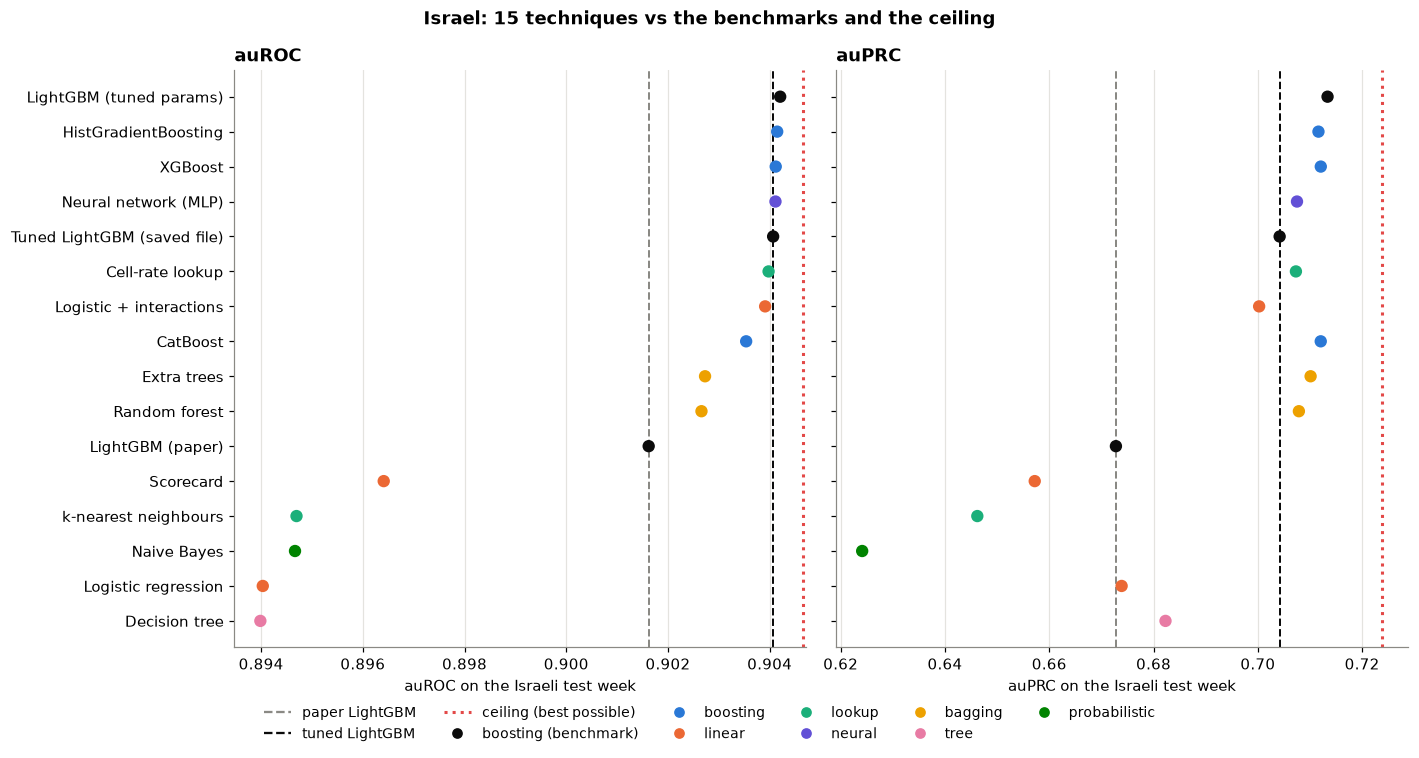

In [7]:
def leaderboard_chart(ax_roc, ax_prc, table, ceiling, big=False):
    order = table.sort_values("auROC").index
    y = np.arange(len(order))
    for ax, metric, ceil in [(ax_roc, "auROC", ceiling["auroc"]), (ax_prc, "auPRC", ceiling["auprc"])]:
        ax.scatter(table.loc[order, metric], y, s=90 if big else 50, zorder=3,
                   color=[FAMILY_COLORS[f] for f in table.loc[order, "family"]])
        ax.axvline(table.loc["LightGBM (paper)", metric], color=GREY, linestyle="--", linewidth=1.3)
        ax.axvline(table.loc[TUNED, metric], color="#0b0b0b", linestyle="--", linewidth=1.3)
        ax.axvline(ceil, color=RED, linestyle=":", linewidth=2)
        ax.set_xlabel(f"{metric} on the Israeli test week")
        ax.grid(axis="y", visible=False)
    ax_roc.set_yticks(y, order)
    ax_prc.tick_params(labelleft=False)
    ax_roc.set_title("auROC", loc="left")
    ax_prc.set_title("auPRC", loc="left")
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], color=GREY, linestyle="--", label="paper LightGBM"),
               Line2D([], [], color="#0b0b0b", linestyle="--", label="tuned LightGBM"),
               Line2D([], [], color=RED, linestyle=":", linewidth=2, label="ceiling (best possible)")]
    handles += [Line2D([], [], marker="o", linestyle="", color=c, label=f) for f, c in FAMILY_COLORS.items()
                if f in set(table["family"])]
    return handles

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
handles = leaderboard_chart(ax1, ax2, leaderboard, ceiling_test)
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.06), fontsize=9)
fig.suptitle("Israel: 15 techniques vs the benchmarks and the ceiling", fontweight="bold")
fig.tight_layout()
plt.show()

**Many techniques beat the paper's LightGBM, but none beats the tuned model.**
- **vs the paper's LightGBM:** five alternative techniques beat it on *both* metrics with CIs excluding 0: HistGradientBoosting, XGBoost, the neural network, the cell-rate lookup table, and logistic regression with pairwise interactions. CatBoost, random forest and extra trees beat it clearly on auPRC (about +0.035–0.039), but their auROC CIs just touch 0.
- **vs the tuned model:** no contender beats it on both. The boosting libraries score about +0.008 auPRC with CIs excluding 0, but their auROC difference is ±0.0001. That's expected, since the tuned model is only 0.0006 auROC below the ceiling.
- **The simple models fall short:** plain logistic regression, Naive Bayes, k-nearest neighbours, the scorecard and the single decision tree all score *below* the paper's model (auROC about 0.894–0.896). What they have in common is that they can't represent interactions between answers (or, for kNN and the tree, do so crudely).
- **A caution on the auPRC differences:** "LightGBM (tuned params)" is the groupmate's exact hyperparameters, retrained here. It "beats" their saved file by +0.009 auPRC. Differences of about 0.01 auPRC can therefore come from training-run details (validation split, seed, number of rounds) rather than from the technique.

## 4.2 Does cross-validation on the training window agree?

To carry models forward without peeking at the test week, every technique is also scored by 5-fold CV on the training window alone. The best model **from each family** is kept, for the top five families. These are the alternatives used in sections 5–8.

In [8]:
cv_rows = {}
for name, factory in MODELS.items():
    r = sp.cross_validate(factory, isr_train, folds=5)
    cv_rows[name] = {"family": sp.FAMILIES[name], "CV auROC": r["cv_auroc"], "CV auPRC": r["cv_auprc"]}
cv_table = pd.DataFrame(cv_rows).T.sort_values("CV auROC", ascending=False)
cv_table["test auROC"] = leaderboard.loc[cv_table.index, "auROC"]

contenders = cv_table[cv_table["family"] != "boosting (benchmark)"]
best_per_family = contenders.groupby("family", sort=False).head(1)
ALTERNATIVES = list(best_per_family.index[:5])
print("Carried forward (best per family, by CV on training data only):", ALTERNATIVES)
print(f"Rank correlation between CV and test auROC: {cv_table['CV auROC'].astype(float).corr(cv_table['test auROC'], method='spearman'):.2f}")
cv_table.style.format({"CV auROC": "{:.4f}", "CV auPRC": "{:.4f}", "test auROC": "{:.4f}"})

Carried forward (best per family, by CV on training data only): ['HistGradientBoosting', 'Neural network (MLP)', 'Random forest', 'Cell-rate lookup', 'Logistic + interactions']
Rank correlation between CV and test auROC: 0.74


,family,CV auROC,CV auPRC,test auROC
HistGradientBoosting,boosting,0.9359,0.7916,0.9041
Neural network (MLP),neural,0.9359,0.7911,0.9041
Random forest,bagging,0.9352,0.7871,0.9027
CatBoost,boosting,0.9352,0.7920,0.9035
XGBoost,boosting,0.9351,0.7926,0.9041
Extra trees,bagging,0.9350,0.7871,0.9027
Cell-rate lookup,lookup,0.9350,0.7842,0.9040
Logistic + interactions,linear,0.9348,0.7839,0.9039
LightGBM (tuned params),boosting (benchmark),0.9341,0.7883,0.9042
LightGBM (paper),boosting (benchmark),0.9331,0.7772,0.9016


Cross-validation on the training window picks the same group of winners as the test week (rank correlation 0.74; the top eight are within about 0.001 of each other in CV). The best of each family carried forward is **HistGradientBoosting, the neural network, random forest, the cell-rate lookup, and logistic + interactions**. That's five different ways to model interactions. CV scores are about 0.03 higher than test scores throughout, for the reason given in section 3.

## 4.3 Would a little tuning change the picture?

Each other boosting library gets a small grid (tree size × learning rate), chosen by 5-fold CV on the training window with `sp.select_and_score`. This is tuning the *alternatives*, only to check the defaults aren't holding them back.

In [9]:
GRIDS = {
    "XGBoost": [{"max_depth": d, "learning_rate": lr} for d in (2, 4, 6) for lr in (0.05, 0.2)],
    "CatBoost": [{"depth": d, "learning_rate": lr} for d in (2, 4, 6) for lr in (0.05, 0.2)],
    "HistGradientBoosting": [{"max_leaf_nodes": n, "learning_rate": lr} for n in (4, 15, 31) for lr in (0.05, 0.2)],
}
rows = []
for name, grid in GRIDS.items():
    candidates = {str(g): (lambda g=g, name=name: lambda **kw: MODELS[name](params=g, **kw))() for g in grid}
    best, table, model = sp.select_and_score(candidates, isr_train, isr_test, folds=5)
    p = model.predict(isr_test)
    m = sp.metrics(y_test, p)
    rows.append({"model": name, "CV-chosen settings": best, "CV auROC range across grid":
                 f"{table['cv_auroc'].min():.4f}–{table['cv_auroc'].max():.4f}",
                 "test auROC (default)": leaderboard.loc[name, "auROC"], "test auROC (CV-chosen)": m["auroc"],
                 "test auPRC (default)": leaderboard.loc[name, "auPRC"], "test auPRC (CV-chosen)": m["auprc"]})
pd.DataFrame(rows).set_index("model").style.format("{:.4f}", subset=pd.IndexSlice[:, ["test auROC (default)",
    "test auROC (CV-chosen)", "test auPRC (default)", "test auPRC (CV-chosen)"]])

,CV-chosen settings,CV auROC range across grid,test auROC (default),test auROC (CV-chosen),test auPRC (default),test auPRC (CV-chosen)
model,,,,,,
XGBoost,"{'max_depth': 6, 'learning_rate': 0.05}",0.9348–0.9352,0.9041,0.9041,0.7121,0.7114
CatBoost,"{'depth': 4, 'learning_rate': 0.05}",0.9348–0.9352,0.9035,0.9035,0.7121,0.7121
HistGradientBoosting,"{'max_leaf_nodes': 4, 'learning_rate': 0.2}",0.9352–0.9365,0.9041,0.9042,0.7116,0.7120


Tuning the other boosting libraries changes nothing that matters. Across each grid the CV auROC varies by at most 0.0013. The CV-chosen settings score within 0.0001 auROC and 0.0007 auPRC of the defaults on the test week. That confirms the defaults aren't holding the alternatives back: on this data almost any reasonable boosting setup reaches the ceiling.

## 4.4 Why does the paper's LightGBM fall short?

The flexible models cluster at the ceiling, and the plain (main-effects only) logistic regression is the furthest below it. That points to **interactions**: the risk from two answers together isn't the sum of their separate risks. The paper's LightGBM uses `feature_fraction=0.2`, so each tree sees only 1–2 of the 8 features and can rarely split on two together. As a diagnostic (not a contender, since it's tuning the existing model), here's the same model with that one setting changed:

In [10]:
diag = {}
for ff in (0.2, 0.5, 1.0):
    p = sp.SymptomModel(params={"feature_fraction": ff}).fit(isr_train).predict(isr_test)
    diag[f"feature_fraction = {ff}" + (" (paper)" if ff == 0.2 else "")] = sp.metrics(y_test, p)
pd.DataFrame(diag).loc[["auroc", "auprc"]].T.style.format("{:.4f}")

,auroc,auprc
feature_fraction = 0.2 (paper),0.9016,0.6728
feature_fraction = 0.5,0.9037,0.7030
feature_fraction = 1.0,0.9041,0.7097


**That one setting explains the whole gap.** With `feature_fraction` raised from 0.2 to 1.0, the paper's own LightGBM goes from 0.902 / 0.673 to **0.904 / 0.710**, level with every flexible alternative. The comparison between the two logistic regressions tells the same story: adding pairwise interactions lifts auROC from 0.894 to 0.904.

So the paper's model wasn't beaten because the alternatives are cleverer. It was handicapped from learning combinations of answers (for example "contact *and* fever"), and any technique that can learn them reaches the ceiling. The groupmate's tuning found the same thing: their tuned `feature_fraction` is 0.72.

## 4.5 Curves

The paper's model, the tuned model, and the alternatives carried forward. The curves sit almost on top of each other. The differences are in the top-left of the precision–recall plot: how well each model orders the highest-risk combinations.

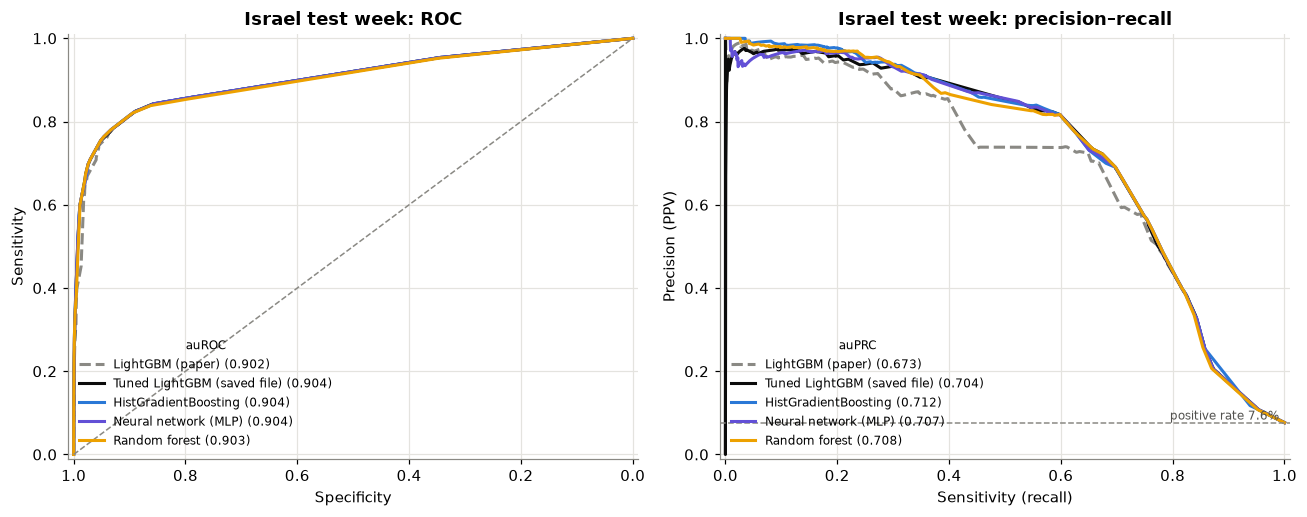

In [11]:
curve_models = ["LightGBM (paper)", TUNED, *ALTERNATIVES[:3]]
palette = {"LightGBM (paper)": GREY, TUNED: "#0b0b0b"}
palette.update({m: FAMILY_COLORS[sp.FAMILIES[m]] for m in ALTERNATIVES})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sp.plot_curves({m: (y_test, zoo_preds[m]) for m in curve_models}, axes=axes, colors=palette,
               linestyles={"LightGBM (paper)": "--"}, title="Israel test week")
axes[1].legend(frameon=False, fontsize=8, loc="lower left", title="auPRC", title_fontsize=8)
plt.tight_layout()
plt.show()

---
# 5. Approaches beyond model type

## 5.1 Ensembles

Do different families make different mistakes that cancel out? The top three alternatives (by CV) are averaged, and separately stacked (a logistic regression on their out-of-fold predictions).

In [12]:
members = {m: MODELS[m] for m in ALTERNATIVES[:3]}
rows = {}
for method in ("average", "stack"):
    p = sp.EnsembleModel(members, method=method).fit(isr_train).predict(isr_test)
    zoo_preds[f"Ensemble ({method})"] = p
    vp, vt = versus(p, zoo_preds["LightGBM (paper)"]), versus(p, zoo_preds[TUNED])
    rows[f"{method} of {', '.join(members)}"] = {
        "auROC": vp["auroc_a"], "auPRC": vp["auprc_a"], "Δ auROC vs paper": fmt_delta(vp, "auroc"),
        "Δ auPRC vs paper": fmt_delta(vp, "auprc"), "Δ auROC vs tuned": fmt_delta(vt, "auroc"),
        "Δ auPRC vs tuned": fmt_delta(vt, "auprc"), "beats tuned": beats(vt)}
pd.DataFrame(rows).T

,auROC,auPRC,Δ auROC vs paper,Δ auPRC vs paper,Δ auROC vs tuned,Δ auPRC vs tuned,beats tuned
"average of HistGradientBoosting, Neural network (MLP), Random forest",0.904101,0.712344,"+0.0025 [+0.0020, +0.0029]","+0.0396 [+0.0337, +0.0452]","+0.0000 [-0.0002, +0.0003]","+0.0082 [+0.0040, +0.0120]",False
"stack of HistGradientBoosting, Neural network (MLP), Random forest",0.904214,0.712579,"+0.0026 [+0.0009, +0.0043]","+0.0398 [+0.0329, +0.0460]","+0.0001 [-0.0015, +0.0018]","+0.0084 [+0.0038, +0.0128]",False


Ensembling doesn't help. The average and the stack of the top three alternatives score 0.904 / 0.712, the same as their members. When every member is already at the ceiling there are no independent errors left to cancel. Like the single models, they beat the paper's LightGBM and match (but don't beat) the tuned model.

## 5.2 Recency weighting

The epidemic changed quickly in spring 2020: testing criteria widened and who got tested changed from week to week. If the test week resembles the *end* of the training window more than its start, weighting recent days more might help. `sp.recency_weights` halves a row's weight every *h* days back from the last training day.

In [13]:
rows = []
for name in ["LightGBM (paper)", *ALTERNATIVES[:2]]:
    unweighted = MODELS[name]().fit(isr_train).predict(isr_test)
    for half_life in (2, 4, 8):
        w = sp.recency_weights(isr_train, half_life_days=half_life)
        b = versus(MODELS[name]().fit(isr_train, sample_weight=w).predict(isr_test), unweighted, n=500)
        rows.append({"model": name, "half-life (days)": half_life, "auROC": b["auroc_a"], "auPRC": b["auprc_a"],
                     "Δ auROC vs unweighted": fmt_delta(b, "auroc"), "Δ auPRC vs unweighted": fmt_delta(b, "auprc")})
pd.DataFrame(rows).set_index(["model", "half-life (days)"]).style.format({"auROC": "{:.4f}", "auPRC": "{:.4f}"})

Recency weighting helps only the model with room to improve. With a 2-day half-life the paper's LightGBM rises by +0.002 auROC / +0.033 auPRC, close to the ceiling. The alternatives, already at the ceiling, move by at most 0.004 auPRC (the MLP slightly *worse* at 2 days). It isn't a new route past the benchmark: it gets the paper's handicapped model to the same place the flexible models already reach.

## 5.3 Extra training data from other countries

Would adding the US and Brazil training periods help the Israeli model? Each technique is trained on all three countries' training data (`sp.pool`), with every feature and a country indicator (`source_feature=True`), then scored on the Israeli test week against the same technique trained on Israel alone.

In [14]:
pooled_train = sp.pool({name: tr for name, (tr, te) in SPLITS.items()})
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # the pooled model has features Israel never collected; expected
    for name in ["LightGBM (paper)", *ALTERNATIVES]:
        own = MODELS[name](missing="absent").fit(isr_train).predict(isr_test)
        p = MODELS[name](features="all", missing="absent", source_feature=True).fit(
            pooled_train, sample_weight="balance_sources").predict(isr_test)
        b = versus(p, own, n=500)
        rows.append({"model": name, "Israel only": b["auroc_b"], "+ US + Brazil": b["auroc_a"],
                     "Δ auROC": fmt_delta(b, "auroc"), "Δ auPRC": fmt_delta(b, "auprc")})
pd.DataFrame(rows).set_index("model").style.format({"Israel only": "{:.4f}", "+ US + Brazil": "{:.4f}"})

,Israel only,+ US + Brazil,Δ auROC,Δ auPRC
model,,,,
LightGBM (paper),0.9003,0.9004,"+0.0000 [-0.0004, +0.0004]","+0.0102 [+0.0070, +0.0132]"
HistGradientBoosting,0.9029,0.9028,"-0.0001 [-0.0002, +0.0000]","-0.0039 [-0.0070, -0.0012]"
Neural network (MLP),0.9027,0.9028,"+0.0001 [-0.0015, +0.0017]","+0.0030 [-0.0008, +0.0067]"
Random forest,0.9027,0.9027,"-0.0000 [-0.0001, +0.0000]","-0.0013 [-0.0023, -0.0002]"
Cell-rate lookup,0.9028,0.9004,"-0.0023 [-0.0026, -0.0020]","-0.0540 [-0.0613, -0.0458]"
Logistic + interactions,0.9026,0.9011,"-0.0015 [-0.0031, +0.0002]","-0.0041 [-0.0098, +0.0011]"


Adding the US and Brazil training data doesn't improve the Israeli model for any technique. Changes are within ±0.002 auROC, except the cell-rate lookup, which loses 0.002 auROC / 0.054 auPRC. Its shrinkage target becomes a logistic regression fitted to all three countries, which is a poor prior for Israel. Israel already has 50,000 training rows covering almost every answer combination, so extra data from countries with different testing practices has nothing to add.

(Both arms here use `missing="absent"`, as pooling needs, which fills 16–17 blank cough/fever values in Israel's training data. That's why the "Israel only" numbers differ slightly from the leaderboard.)

---
# 6. Bias check

The gains above are on all 8 features. `notebook.ipynb` showed three symptoms (sore throat, shortness of breath, headache) were recorded mostly for people who tested positive, and `alternative-data` 4.6 showed contact alone carries much of the signal. Do the alternatives still beat the paper's model without them? The groupmate's hyperparameters are retrained for this ("LightGBM (tuned params)"), since the saved model can't drop features.

In [15]:
BIASED = ["sore_throat", "shortness_of_breath", "headache"]
FEATURE_SETS = {
    "all 8 features": F,
    "without the 3 biased symptoms": [f for f in F if f not in BIASED],
    "without contact": [f for f in F if f != "contact"],
    "without both": [f for f in F if f not in BIASED + ["contact"]],
}
BIAS_MODELS = ["LightGBM (paper)", "LightGBM (tuned params)", *ALTERNATIVES]
rows, bias_preds = [], {}
for set_name, feats in FEATURE_SETS.items():
    ceiling = sp.oracle_ceiling(isr_test, feats)
    for name in BIAS_MODELS:
        bias_preds[(set_name, name)] = MODELS[name](features=feats).fit(isr_train).predict(isr_test)
    for name in BIAS_MODELS:
        p = bias_preds[(set_name, name)]
        vp = versus(p, bias_preds[(set_name, "LightGBM (paper)")], n=500)
        vt = versus(p, bias_preds[(set_name, "LightGBM (tuned params)")], n=500)
        rows.append({"features": set_name, "model": name, "auROC": vp["auroc_a"], "auPRC": vp["auprc_a"],
                     "auROC gap to ceiling": ceiling["auroc"] - vp["auroc_a"],
                     "auPRC gap to ceiling": ceiling["auprc"] - vp["auprc_a"],
                     "beats paper": beats(vp), "beats tuned params": beats(vt)})
    rows.append({"features": set_name, "model": "ceiling", "auROC": ceiling["auroc"], "auPRC": ceiling["auprc"]})
bias = pd.DataFrame(rows).set_index(["features", "model"])
bias.style.format("{:.4f}", subset=["auROC", "auPRC", "auROC gap to ceiling", "auPRC gap to ceiling"], na_rep="")\
    .map(lambda v: "font-weight: bold; color: #1baf7a" if v is True else "", subset=["beats paper", "beats tuned params"])

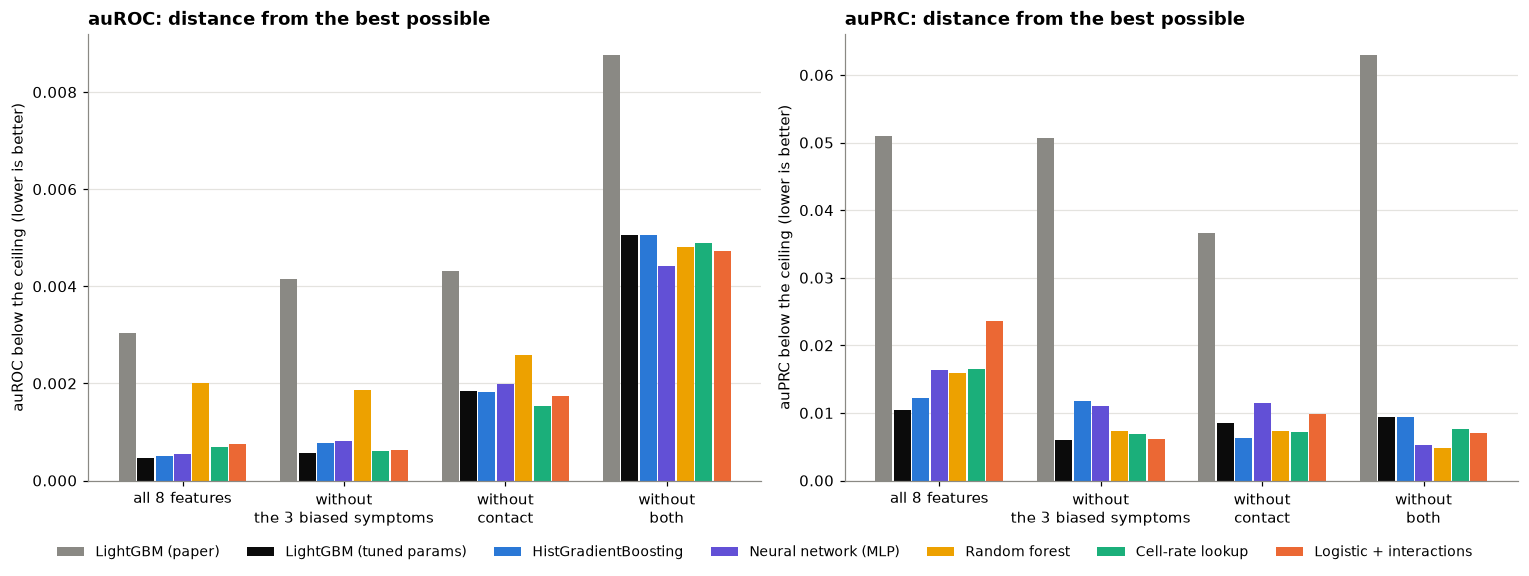

In [16]:
def gap_chart(axes, big=False):
    sets, models = list(FEATURE_SETS), BIAS_MODELS
    width = 0.8 / len(models)
    colors = {"LightGBM (paper)": GREY, "LightGBM (tuned params)": "#0b0b0b"}
    colors.update({m: FAMILY_COLORS[sp.FAMILIES[m]] for m in ALTERNATIVES})
    for ax, metric in zip(axes, ["auROC", "auPRC"]):
        for j, m in enumerate(models):
            vals = [bias.loc[(s, m), f"{metric} gap to ceiling"] for s in sets]
            ax.bar(np.arange(len(sets)) + (j - (len(models) - 1) / 2) * width, vals, width * 0.92,
                   color=colors[m], label=m)
        ax.set_xticks(range(len(sets)), [s.replace("without ", "without\n") for s in sets])
        ax.set_ylabel(f"{metric} below the ceiling (lower is better)")
        ax.set_title(f"{metric}: distance from the best possible", loc="left")
        ax.grid(axis="x", visible=False)
    return axes[0].get_legend_handles_labels()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
handles, labels = gap_chart(axes)
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, -0.05), fontsize=9)
fig.tight_layout()
plt.show()

**The gains survive the bias check.** Under every feature set, the alternatives beat the paper's LightGBM on both metrics with CIs excluding 0. The only exception is random forest on all 8 features, as in section 4.1. The paper's model is consistently the furthest from the ceiling:
- 0.003–0.009 auROC and 0.04–0.06 auPRC below it;
- against at most 0.005 auROC and 0.024 auPRC for everything else.

So criterion 3 is met against the paper's model: the improvement comes from modelling interactions, not from leaning on the biased symptoms.

Against the tuned hyperparameters, nothing wins with all 8 features, without the biased symptoms, or without contact. Without both (4 features: cough, fever, age and sex), the MLP, cell-rate lookup and logistic + interactions do edge past them, by under 0.001 auROC and up to 0.004 auPRC. That's a trivial margin on a model that is a long way from useful (auROC 0.75).

The ceiling itself drops sharply as features are removed (0.905 → 0.876 → 0.804 → 0.750). **What the model is given matters far more than which model it is.**

## 6.1 What do the models lean on?

SHAP values for the paper's model, the tuned hyperparameters, and two alternatives, with the same features in the same order (as in `alternative-data` 4.3). For `EstimatorModel`s, `shap_values` is model-agnostic: exact Shapley values computed on the distinct answer combinations.

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


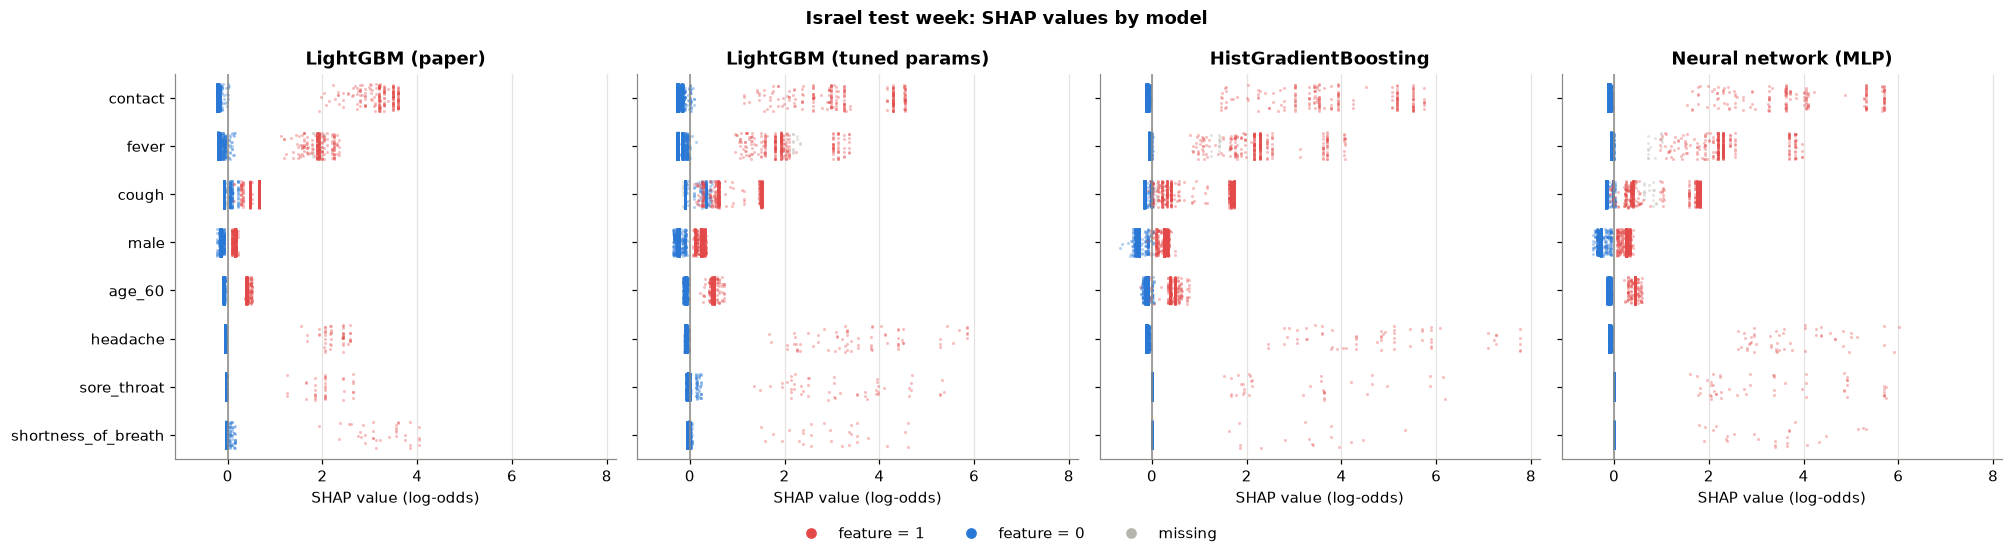

,LightGBM (paper),LightGBM (tuned params),HistGradientBoosting,Neural network (MLP)
contact,28%,24%,21%,22%
fever,25%,23%,15%,16%
cough,11%,15%,19%,20%
male,11%,14%,18%,17%
age_60,10%,9%,11%,11%
headache,7%,8%,12%,11%
sore_throat,4%,4%,2%,2%
shortness_of_breath,4%,3%,1%,1%


In [17]:
shap_models = ["LightGBM (paper)", "LightGBM (tuned params)", *ALTERNATIVES[:2]]
explanations = {name: MODELS[name]().fit(isr_train).shap_values(isr_test) for name in shap_models}
order = sp.shap_feature_order(explanations)
sp.plot_shap_grid(explanations, order=order, sharex=True, suptitle="Israel test week: SHAP values by model")
plt.show()
mean_abs = pd.DataFrame({name: pd.Series(np.abs(e.values).mean(0), index=e.feature_names) for name, e in explanations.items()}).loc[order]
(mean_abs / mean_abs.sum()).style.format("{:.0%}").set_caption("Share of total mean |SHAP| per feature")

All four models lean on the same features in the same order: contact, then fever, then cough and sex. The flexible models (the tuned hyperparameters, HistGradientBoosting, the neural network) give *rare combinations* much larger effects: headache, sore throat and shortness of breath reach +4 to +8 log-odds, against +1 to +4 for the paper's model. That's what modelling interactions looks like. The biased symptoms' share of total importance is unchanged (about 14–15% in every model), so the gains don't come from relying on them more.

---
# 7. All three countries

Does any technique improve *and* generalise? The alternatives carried forward from section 4.2 are run on every country, with the paper's LightGBM and the tuned hyperparameters as references. As in `alternative-data`, `missing="absent"` is used throughout (blanks mean "not reported", except for age and sex), and the LightGBM models average 5 seeds (their single runs vary with the early-stopping split). The other techniques are deterministic or close to it, so they use one.

In [18]:
CROSS_MODELS = ["LightGBM (paper)", "LightGBM (tuned params)", *ALTERNATIVES]
def cross_kwargs(name):
    return dict(missing="absent", n_models=5 if name.startswith("LightGBM") else 1)

pvs = {}
for name in CROSS_MODELS:
    start = time.perf_counter()
    pvs[name] = sp.pool_vs_specialist(SPLITS, model_factory=MODELS[name], **cross_kwargs(name))
    print(f"{name}: {time.perf_counter() - start:.0f}s")
pvs_all = pd.concat([r.assign(technique=name) for name, r in pvs.items()], ignore_index=True)
ceilings = {name: sp.oracle_ceiling(te, sp.available_features(te)) for name, (tr, te) in SPLITS.items()}

LightGBM (paper): 52s


LightGBM (tuned params): 25s


HistGradientBoosting: 10s


Neural network (MLP): 16s


Random forest: 12s


Cell-rate lookup: 4s


Logistic + interactions: 12s


## 7a. Each country on its own

Each technique trained and tested on one country (all its features). The "ceiling" row is that country's best possible score with its own features.

In [19]:
def by_country(variant, metric="auroc"):
    t = pvs_all[pvs_all["model"] == variant].pivot(index="technique", columns="test", values=metric)
    return t.reindex(index=CROSS_MODELS, columns=list(SPLITS))

specialists = by_country("specialist")
spec_table = pd.concat([specialists, pd.DataFrame({n: c["auroc"] for n, c in ceilings.items()}, index=["ceiling"])])
print("auROC, each country's own test period")
spec_table.style.format("{:.3f}").highlight_max(axis=0, subset=pd.IndexSlice[CROSS_MODELS, :], props="font-weight: bold")

auROC, each country's own test period


,israel,carbon_health,brazil
LightGBM (paper),0.901,0.708,0.636
LightGBM (tuned params),0.903,0.704,0.638
HistGradientBoosting,0.903,0.705,0.638
Neural network (MLP),0.903,0.704,0.638
Random forest,0.903,0.704,0.644
Cell-rate lookup,0.903,0.676,0.641
Logistic + interactions,0.903,0.695,0.637
ceiling,0.905,0.815,0.746


In [20]:
print("auPRC, each country's own test period (positive rates: " +
      ", ".join(f"{n} {te.y.mean():.1%}" for n, (tr, te) in SPLITS.items()) + ")")
by_country("specialist", "auprc").style.format("{:.3f}").highlight_max(axis=0, props="font-weight: bold")

auPRC, each country's own test period (positive rates: israel 7.6%, carbon_health 0.7%, brazil 47.0%)


test,israel,carbon_health,brazil
technique,,,
LightGBM (paper),0.681,0.094,0.583
LightGBM (tuned params),0.713,0.092,0.584
HistGradientBoosting,0.711,0.084,0.585
Neural network (MLP),0.706,0.094,0.582
Random forest,0.709,0.090,0.585
Cell-rate lookup,0.707,0.081,0.584
Logistic + interactions,0.699,0.092,0.584


**On each country alone, the best technique depends on the data, and the differences are small.**
- **Israel:** every flexible technique scores 0.903; the paper's LightGBM 0.901.
- **US:** the paper's LightGBM is *best* (0.708). HistGradientBoosting, the MLP, random forest and the tuned hyperparameters follow at 0.704–0.705, and the cell-rate lookup is clearly worst (0.676). With only 960 positive training cases and 13 features (thousands of possible combinations), a lookup table has too few cases per combination. The paper's heavy regularisation (each tree sees only 20% of the features) suits noisy, sparse data like this.
- **Brazil:** everything lands between 0.636 and 0.644. Random forest is marginally best.

The ceilings for the US (0.815) and Brazil (0.746) look like headroom, but they aren't reachable. With many features and few positives, a lookup fitted on the test set itself "memorises" small groups, so the ceiling overstates what's possible. It's a reliable bound for Israel only, where nearly every combination is common.

## 7b. One model for all three countries (pooling)

`sp.pool_vs_specialist` trains, for each technique, one pooled model on all three countries' training periods, in three variants:
- **shared features**: only the 6 features every country collected;
- **all features**: every feature any country has, NaN where a country never collected it;
- **all features + country**: as above, plus a 0/1 column per country (`source_feature=True`).

Each pooled model is scored on each country's test period. The table shows the difference from that technique's own specialist (positive = pooling helps).

In [21]:
VARIANTS = ["pooled, shared features", "pooled, all features", "pooled, all features + country"]
pool_delta = pd.concat({v: by_country(v) - specialists for v in VARIANTS}, axis=1)
pool_delta.style.format("{:+.3f}").background_gradient(cmap="RdBu", vmin=-0.08, vmax=0.08)

In [22]:
print("Best score per country, any technique, any setup:")
best = pvs_all.loc[pvs_all.groupby("test")["auroc"].idxmax(), ["test", "technique", "model", "auroc", "auprc"]]
best.set_index("test").reindex(list(SPLITS)).round(3)

Best score per country, any technique, any setup:


,technique,model,auroc,auprc
test,,,,
israel,LightGBM (tuned params),specialist,0.903,0.713
carbon_health,LightGBM (paper),specialist,0.708,0.094
brazil,LightGBM (paper),"pooled, shared features",0.691,0.613


In [23]:
rows = []
for name in CROSS_MODELS:
    preds = pvs[name].attrs["predictions"]
    y, p_spec = preds[("brazil", "specialist")]
    b = sp.paired_bootstrap(y, preds[("brazil", "pooled, shared features")][1], p_spec, n=500)
    rows.append({"technique": name, "specialist": b["auroc_b"], "pooled, shared": b["auroc_a"],
                 "Δ auROC": fmt_delta(b, "auroc"), "Δ auPRC": fmt_delta(b, "auprc"), "reliably better": beats(b)})
print("Brazil: pooled (shared features) vs specialist")
pd.DataFrame(rows).set_index("technique").style.format({"specialist": "{:.3f}", "pooled, shared": "{:.3f}"})

Brazil: pooled (shared features) vs specialist


,specialist,"pooled, shared",Δ auROC,Δ auPRC,reliably better
technique,,,,,
LightGBM (paper),0.636,0.691,"+0.0548 [+0.0470, +0.0638]","+0.0305 [+0.0181, +0.0446]",True
LightGBM (tuned params),0.638,0.669,"+0.0316 [+0.0237, +0.0396]","+0.0102 [-0.0005, +0.0204]",False
HistGradientBoosting,0.638,0.671,"+0.0333 [+0.0255, +0.0417]","+0.0123 [+0.0020, +0.0224]",True
Neural network (MLP),0.638,0.672,"+0.0339 [+0.0267, +0.0420]","+0.0164 [+0.0054, +0.0275]",True
Random forest,0.644,0.671,"+0.0266 [+0.0186, +0.0348]","+0.0120 [+0.0011, +0.0220]",True
Cell-rate lookup,0.641,0.670,"+0.0291 [+0.0213, +0.0373]","+0.0129 [+0.0019, +0.0232]",True
Logistic + interactions,0.637,0.673,"+0.0364 [+0.0278, +0.0448]","+0.0112 [+0.0003, +0.0222]",True


In [24]:
# Is Brazil's gain from pooling, or from dropping its extra features? Same techniques, Brazil alone, shared features only
btr, bte = SPLITS["brazil"]
shared = pvs["LightGBM (paper)"].attrs["shared_features"]
rows = {}
for name in CROSS_MODELS:
    alone_shared = MODELS[name](features=shared, **cross_kwargs(name)).fit(btr).evaluate(bte, bootstrap=0)["auroc"]
    rows[name] = {"Brazil alone, all features": specialists.loc[name, "brazil"], "Brazil alone, shared features": alone_shared,
                  "pooled, shared features": by_country("pooled, shared features").loc[name, "brazil"]}
pd.DataFrame(rows).T.style.format("{:.3f}")

,"Brazil alone, all features","Brazil alone, shared features","pooled, shared features"
LightGBM (paper),0.636,0.644,0.691
LightGBM (tuned params),0.638,0.666,0.669
HistGradientBoosting,0.638,0.662,0.671
Neural network (MLP),0.638,0.656,0.672
Random forest,0.644,0.662,0.671
Cell-rate lookup,0.641,0.662,0.670
Logistic + interactions,0.637,0.660,0.673


**Pooling helps Brazil, for every technique, and that's the only place it helps.**
- **Shared features:** every technique gains in Brazil (+0.027 to +0.055 auROC), and the gain is reliably positive for all but the tuned hyperparameters (whose auPRC CI touches 0). Israel's −0.12 is the cost of losing contact and sex, not of pooling. The US loses about 0.02–0.03 because it loses its extra symptoms (loss of smell and taste).
- **All features (with or without a country indicator):** the pooled model is roughly as good as each country's specialist, for every technique. That repeats `alternative-data` 4.4's LightGBM result across techniques. Two exceptions point the same way: the neural network gains +0.023 in Brazil with the country indicator, while the cell-rate lookup and logistic + interactions lose 0.03–0.04 in the US. The models that hard-code the missing-value structure struggle when three countries' blanks are mixed together.
- **Where Brazil's gain comes from:** the last table splits it in two. Dropping Brazil's extra symptoms alone accounts for +0.008 (the paper's LightGBM) to +0.028 (the tuned hyperparameters). Pooling adds the rest: +0.047 for the paper's LightGBM, but only +0.003 to +0.016 for the others.
  - **Why dropping symptoms might help:** Brazil's test year is 2022, the Omicron period, when loss of smell and taste were widely reported to be less common than with earlier variants. A model leaning on them would then be miscalibrated (this wasn't checked directly here).
  - **What the result is:** the best Brazil score of the whole study is the paper's LightGBM pooled on shared features, **0.691**.

## 7c. Train on one country, test on another

`sp.compare(..., unseen_on="test", model_factory=...)` on the shared features: each technique trained on one country and scored on every country's test period. The diagonal is "within" (same country, later period); the rest is "unseen".

In [25]:
transfer = {}
for name in CROSS_MODELS:
    transfer[name] = sp.compare(DATASETS, splits=SPLITS, unseen_on="test", model_factory=MODELS[name], **cross_kwargs(name))
transfer_all = pd.concat([r.assign(technique=name) for name, r in transfer.items()], ignore_index=True)
unseen = transfer_all[transfer_all["kind"] == "unseen"]
t = unseen.pivot_table(index="technique", columns=["train", "test"], values="auroc").reindex(CROSS_MODELS)
t["mean"] = t.mean(axis=1)
t.style.format("{:.3f}").highlight_max(axis=0, props="font-weight: bold")

Trained on one country and tested on another, the techniques are again close. Averaged over the six pairs:
- **Best:** the tuned hyperparameters (0.705), random forest and the cell-rate lookup (0.702), logistic + interactions (0.700).
- **Middle:** HistGradientBoosting (0.697) and the paper's LightGBM (0.690).
- **Worst:** the neural network (0.677).

The biggest single difference is Brazil → US, where the paper's LightGBM (0.607) trails the others (0.656–0.676).

The more regularised models travel slightly better, but no technique changes the overall picture: about 0.61–0.77 on an unseen country, against 0.64–0.90 at home.

## 7d. A country the model has never seen

`sp.leave_one_out(..., model_factory=...)`: pool two countries' training data and test on the third country's test period. Two variants: shared features only, and all features plus a country indicator (the held-out country's indicator columns are all 0).

In [26]:
loo = []
for name in CROSS_MODELS:
    kw = cross_kwargs(name)
    loo.append(sp.leave_one_out(DATASETS, splits=SPLITS, features="common", model_factory=MODELS[name], **kw)
               .assign(technique=name, variant="shared features"))
    loo.append(sp.leave_one_out(DATASETS, splits=SPLITS, features="all", model_factory=MODELS[name],
                                source_feature=True, **kw).assign(technique=name, variant="all features + country"))
loo = pd.concat(loo, ignore_index=True)
loo_table = loo.pivot_table(index="technique", columns=["variant", "held_out"], values="auroc").reindex(CROSS_MODELS)
loo_table = loo_table.reindex(columns=pd.MultiIndex.from_product([["shared features", "all features + country"], list(SPLITS)]))
loo_table.style.format("{:.3f}").highlight_max(axis=0, props="font-weight: bold")

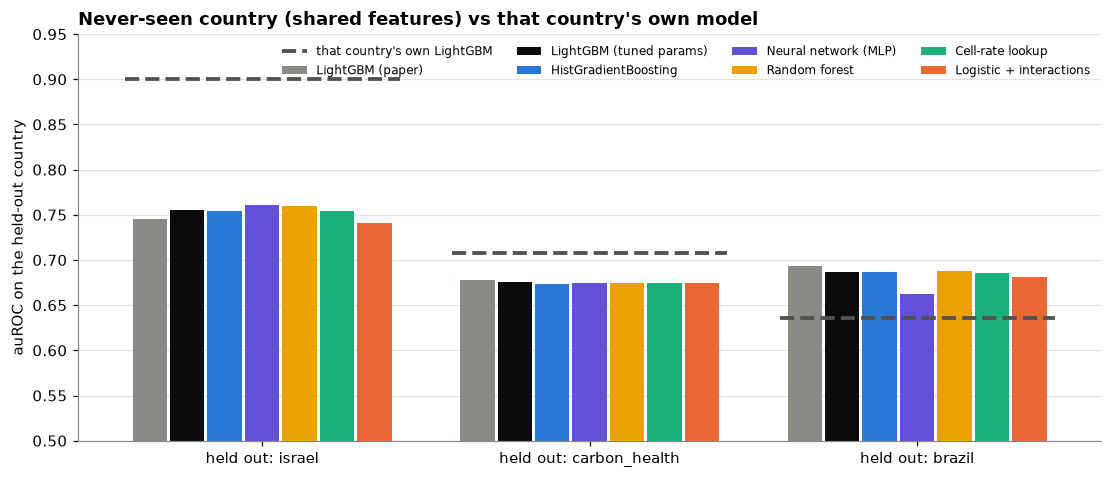

In [27]:
def loo_chart(ax, big=False):
    shared_loo = loo[loo["variant"] == "shared features"]
    names = list(SPLITS)
    width = 0.8 / len(CROSS_MODELS)
    colors = {"LightGBM (paper)": GREY, "LightGBM (tuned params)": "#0b0b0b"}
    colors.update({m: FAMILY_COLORS[sp.FAMILIES[m]] for m in ALTERNATIVES})
    for j, m in enumerate(CROSS_MODELS):
        vals = shared_loo[shared_loo["technique"] == m].set_index("held_out").loc[names, "auroc"]
        ax.bar(np.arange(len(names)) + (j - (len(CROSS_MODELS) - 1) / 2) * width, vals - 0.5, width * 0.92,
               bottom=0.5, color=colors[m], label=m)
    for i, n in enumerate(names):
        ax.plot([i - 0.42, i + 0.42], [specialists.loc["LightGBM (paper)", n]] * 2, color="#52514e", linewidth=2.5,
                linestyle="--", label="that country's own LightGBM" if i == 0 else None)
    ax.set_xticks(range(len(names)), [f"held out: {n}" for n in names])
    ax.set_ylim(0.5, 0.95)
    ax.set_ylabel("auROC on the held-out country")
    ax.grid(axis="x", visible=False)
    return ax.get_legend_handles_labels()

fig, ax = plt.subplots(figsize=(12, 4.8))
handles, labels = loo_chart(ax)
ax.legend(handles, labels, frameon=False, fontsize=8, ncol=4, loc="upper right")
ax.set_title("Never-seen country (shared features) vs that country's own model", loc="left")
plt.show()

**On a country no model has seen, the choice of technique barely matters.**
- **Shared features:**
  - Israel held out: 0.741–0.761 (the MLP and random forest are best).
  - US held out: 0.674–0.678 for every technique.
  - Brazil held out: 0.663–0.693 (the paper's LightGBM is best).
- **Compared with each country's own model:** a model trained on local data stays far better for Israel (0.90) and better for the US (0.71). In Brazil, models that have *never seen Brazilian data* beat Brazil's own model (about 0.69 vs 0.64). That fits the pooling result: Brazil's own training years are a poor guide to its 2022 test year.
- **All features plus a country indicator:** this variant is usually *worse* for an unseen country, sometimes dramatically (the MLP scores 0.50 on Israel). The held-out country's indicator columns are all 0, a combination never seen in training, and its pattern of missing features is new too. Random forest is the robust exception: 0.710 on Israel, and **0.701 on the US, the best unseen-US score of any setup**.
- **Lesson:** to generalise to a new country, use features every country collects, and don't rely on country indicators.

---
# 8. Head-to-head with the tuned model, on its own split

The groupmate's saved model was trained on their split (all rows, unknown sex kept as missing). For a strictly fair comparison, the top alternative (by CV, section 4.2) and the runner-up are retrained on exactly that training data and scored on their 48,462-row test week against the saved file.

In [28]:
y_theirs = their_test["y"].values
tuned_theirs = tuned_predict(their_test)
rows = []
for name in ALTERNATIVES[:2]:
    p = MODELS[name]().fit(their_train).predict(their_test)
    b = sp.paired_bootstrap(y_theirs, p, tuned_theirs, n=2000)
    rows.append({"model": name, "auROC": b["auroc_a"], "auPRC": b["auprc_a"], "tuned auROC": b["auroc_b"],
                 "tuned auPRC": b["auprc_b"], "Δ auROC": fmt_delta(b, "auroc"), "Δ auPRC": fmt_delta(b, "auprc"),
                 "P(not better), auROC": b["p_auroc"], "P(not better), auPRC": b["p_auprc"], "beats tuned": beats(b)})
pd.DataFrame(rows).set_index("model").style.format("{:.4f}", subset=["auROC", "auPRC", "tuned auROC", "tuned auPRC"])\
    .format("{:.2f}", subset=["P(not better), auROC", "P(not better), auPRC"])

,auROC,auPRC,tuned auROC,tuned auPRC,Δ auROC,Δ auPRC,"P(not better), auROC","P(not better), auPRC",beats tuned
model,,,,,,,,,
HistGradientBoosting,0.9030,0.7104,0.9024,0.7000,"+0.0005 [-0.0012, +0.0023]","+0.0105 [+0.0057, +0.0155]",0.28,0.00,False
Neural network (MLP),0.9028,0.7073,0.9024,0.7000,"+0.0003 [-0.0005, +0.0013]","+0.0073 [+0.0032, +0.0118]",0.24,0.00,False


On the groupmate's own split and test week, neither alternative clearly beats their saved model:
- **HistGradientBoosting:** 0.9030 / 0.7104 against 0.9024 / 0.7000. The auROC difference is +0.0005, with a CI from −0.0012 to +0.0023 (in 28% of resamples it's not better).
- **Neural network:** +0.0003 auROC, similarly inconclusive.

Both are reliably better on auPRC (+0.010 and +0.007). But section 4.1 showed that simply retraining the tuned hyperparameters shifts auPRC by about 0.009, so that's within what training-run details produce.

**Verdict: no alternative meets the "outperform" criteria against the tuned model.** They *equal* it, with default settings and no tuning.

---
# 9. Summary

**Can a different technique outperform the paper's model?**
- **Against the paper's LightGBM: yes.** Five alternative techniques beat it on both auROC and auPRC with paired-bootstrap CIs excluding 0: HistGradientBoosting, XGBoost, a small neural network, a cell-rate lookup table, and logistic regression with pairwise interactions. The gain survives removing the biased symptoms, contact, or both.
- **Against the groupmate's tuned LightGBM: no.** Nothing beats it on both metrics. Default settings, CV-chosen settings, ensembles and recency weighting all give the same result, and so does training on exactly its split. The alternatives *match* it without any tuning.

**Why:**
1. **There is no headroom.** With 8 yes/no answers and about 200 combinations in the test week, the best possible auROC is 0.905. The tuned model is 0.0006 below that. The CV-vs-test gap (0.935 vs 0.904) is a shift between weeks that no model can recover.
2. **The paper's shortfall is one setting.** `feature_fraction=0.2` stops its trees from learning interactions between answers. Every technique that can learn them reaches the ceiling (the same LightGBM with `feature_fraction=1.0` does too). The simplest such model, logistic regression with pairwise interactions, is fully inspectable.

**Do the techniques generalise?**
- **Each country alone:** no technique wins everywhere. Israel: all flexible models tie. US: the paper's own heavily regularised LightGBM is best, and the lookup table worst. Brazil: everything is within 0.01.
- **Pooling:** helps only Brazil, by about 0.03–0.055 auROC for every technique. Part comes from dropping Brazil's extra symptoms, and the rest from pooling itself.
- **A never-seen country:** techniques are within about 0.02–0.03 of each other. Using shared features matters more than the technique, and country indicators backfire.

**Overall:** on this kind of data, *what* the model is given (which features, recorded how, from which population) matters far more than *which* model it is. Once a model can capture interactions, the choice of technique moves results by about 0.001 auROC. Changing the features or the country moves them by 0.05–0.15.

---
# 10. Presentation assets and takeaways

Slide-ready versions of the key results, saved as high-resolution PNGs in `assets/alternative-modelling/` with large fonts and a white background.

In [29]:
ASSETS = Path("assets/alternative-modelling")
ASSETS.mkdir(parents=True, exist_ok=True)
DISPLAY = {"israel": "Israel", "carbon_health": "US (Carbon Health)", "brazil": "Brazil (Acre)"}
SLIDE_STYLE = {"font.size": 14, "axes.titlesize": 17, "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13,
               "legend.fontsize": 12, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}

def save(fig, name):
    path = ASSETS / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"saved {path}")

### Asset 1: there's almost no headroom

saved assets/alternative-modelling/1_headroom.png


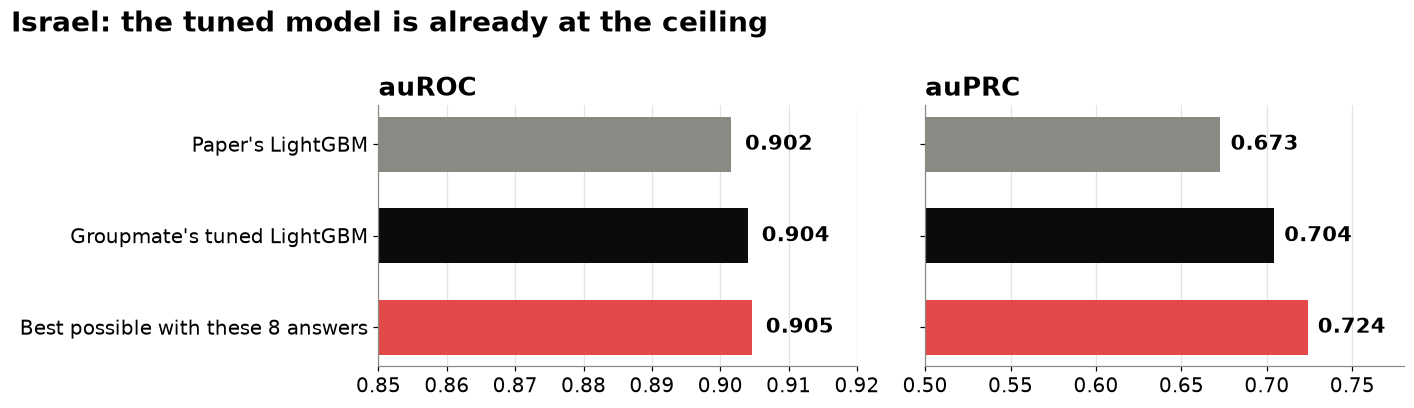

In [30]:
with plt.rc_context(SLIDE_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    labels = ["Paper's LightGBM", "Groupmate's tuned LightGBM", "Best possible with these 8 answers"]
    colors = [GREY, "#0b0b0b", RED]
    for ax, metric, lo in [(axes[0], "auroc", 0.85), (axes[1], "auprc", 0.5)]:
        vals = [headroom.loc["paper LightGBM", metric], headroom.loc["tuned LightGBM", metric], ceiling_test[metric]]
        ax.barh(range(3), [v - lo for v in vals], left=lo, color=colors, height=0.6)
        for i, v in enumerate(vals):
            ax.text(v + (0.002 if metric == "auroc" else 0.006), i, f"{v:.3f}", va="center", fontsize=14, fontweight="bold")
        ax.set_yticks(range(3), labels if metric == "auroc" else [""] * 3)
        ax.invert_yaxis()
        ax.set_xlim(lo, 0.92 if metric == "auroc" else 0.78)
        ax.set_title("auROC" if metric == "auroc" else "auPRC", loc="left")
        ax.grid(axis="y", visible=False)
    fig.suptitle("Israel: the tuned model is already at the ceiling", fontweight="bold", fontsize=18, x=0.01, ha="left")
    fig.tight_layout()
    save(fig, "1_headroom")
    plt.show()

### Asset 2: fifteen techniques, one ceiling

saved assets/alternative-modelling/2_leaderboard.png


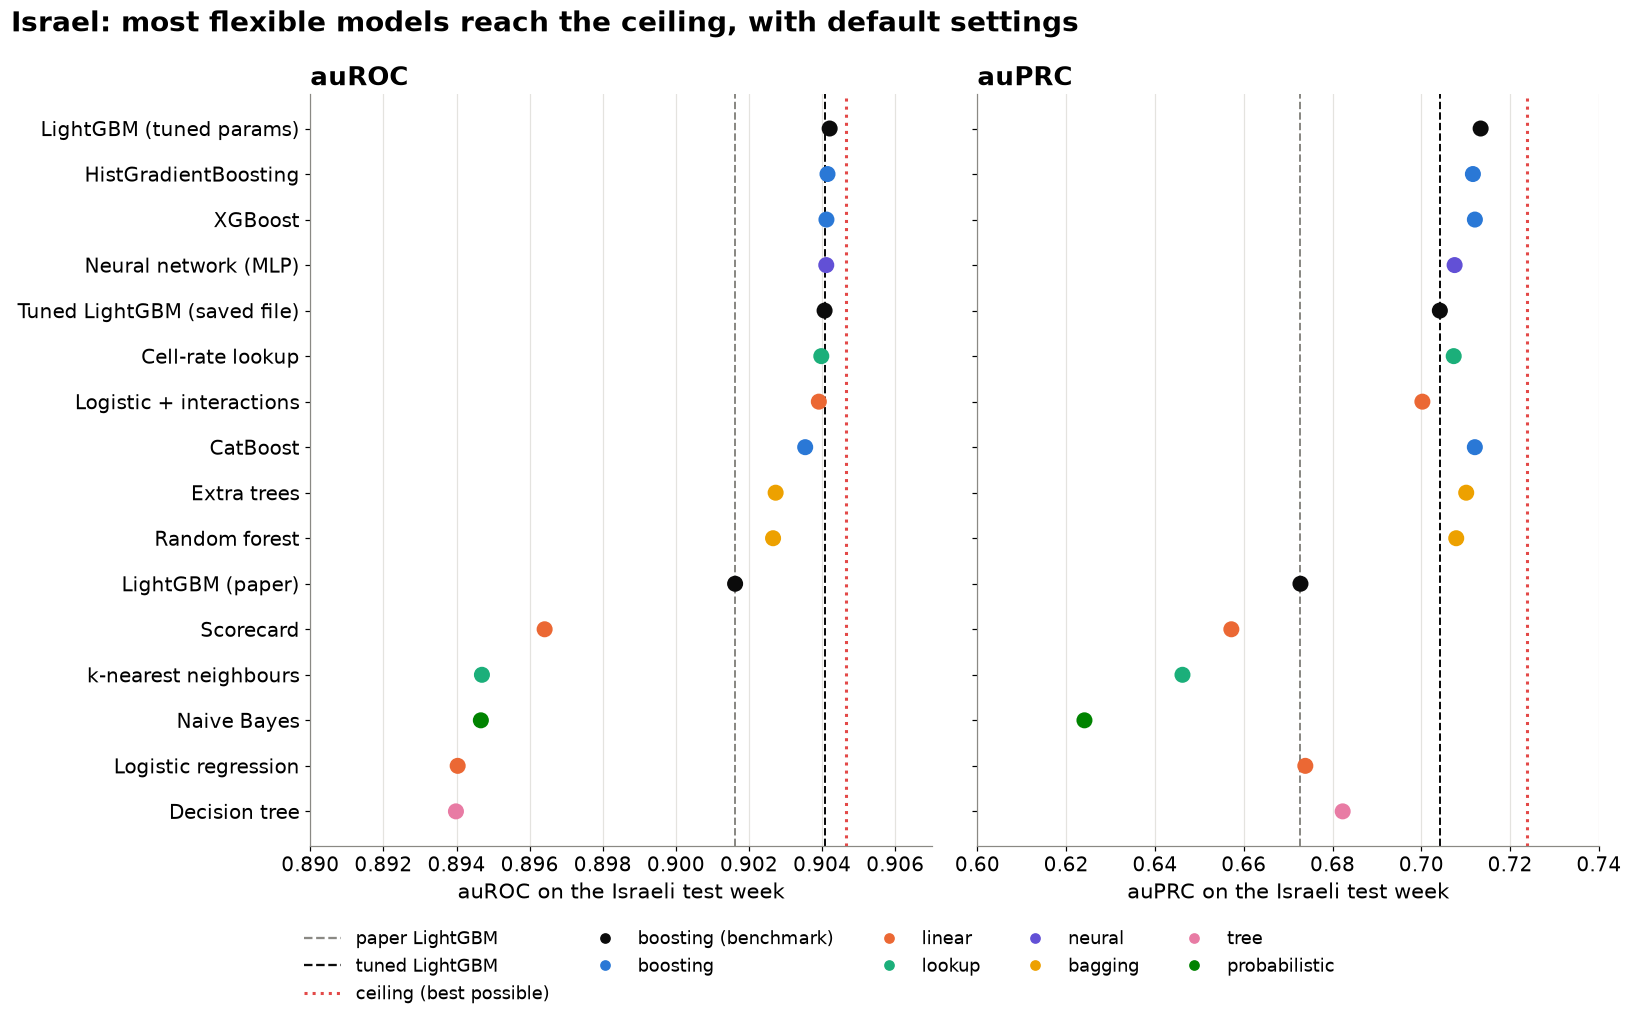

In [31]:
with plt.rc_context(SLIDE_STYLE):
    table = leaderboard.drop(index=["Ensemble (average)", "Ensemble (stack)"], errors="ignore")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8.5), sharey=True)
    handles = leaderboard_chart(ax1, ax2, table, ceiling_test, big=True)
    ax1.set_xlim(0.89, 0.907)
    ax2.set_xlim(0.6, 0.74)
    fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.1))
    fig.suptitle("Israel: most flexible models reach the ceiling, with default settings", fontweight="bold",
                 fontsize=18, x=0.01, ha="left")
    fig.tight_layout()
    save(fig, "2_leaderboard")
    plt.show()

### Asset 3: the gains aren't from the biased symptoms

saved assets/alternative-modelling/3_bias_check.png


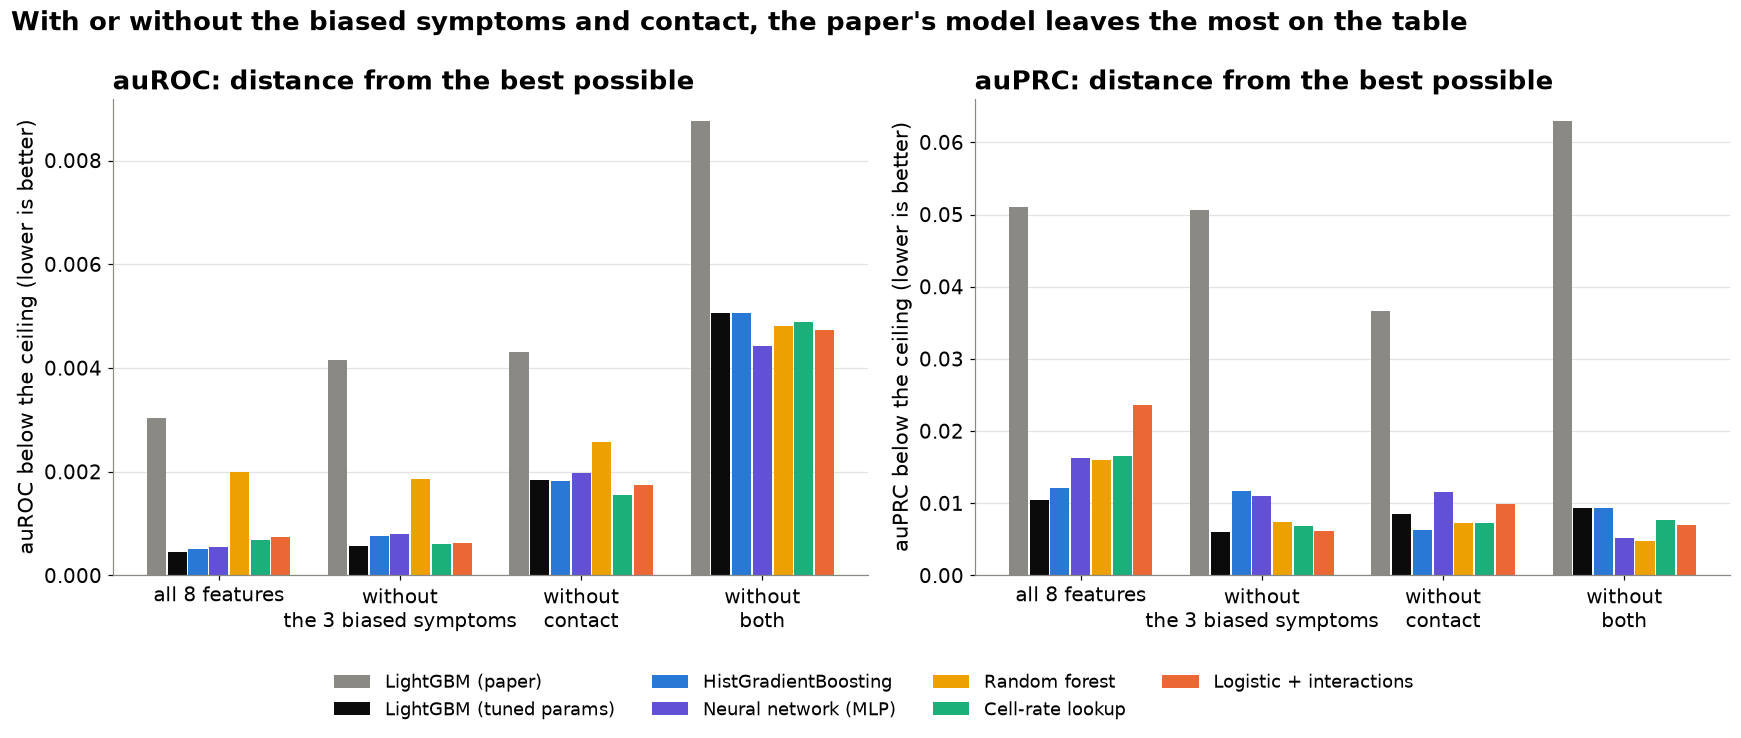

In [32]:
with plt.rc_context(SLIDE_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    handles, labels = gap_chart(axes, big=True)
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle("With or without the biased symptoms and contact, the paper's model leaves the most on the table",
                 fontweight="bold", fontsize=17, x=0.01, ha="left")
    fig.tight_layout()
    save(fig, "3_bias_check")
    plt.show()

### Asset 4: pooling, technique by country

saved assets/alternative-modelling/4_pooling_by_technique.png


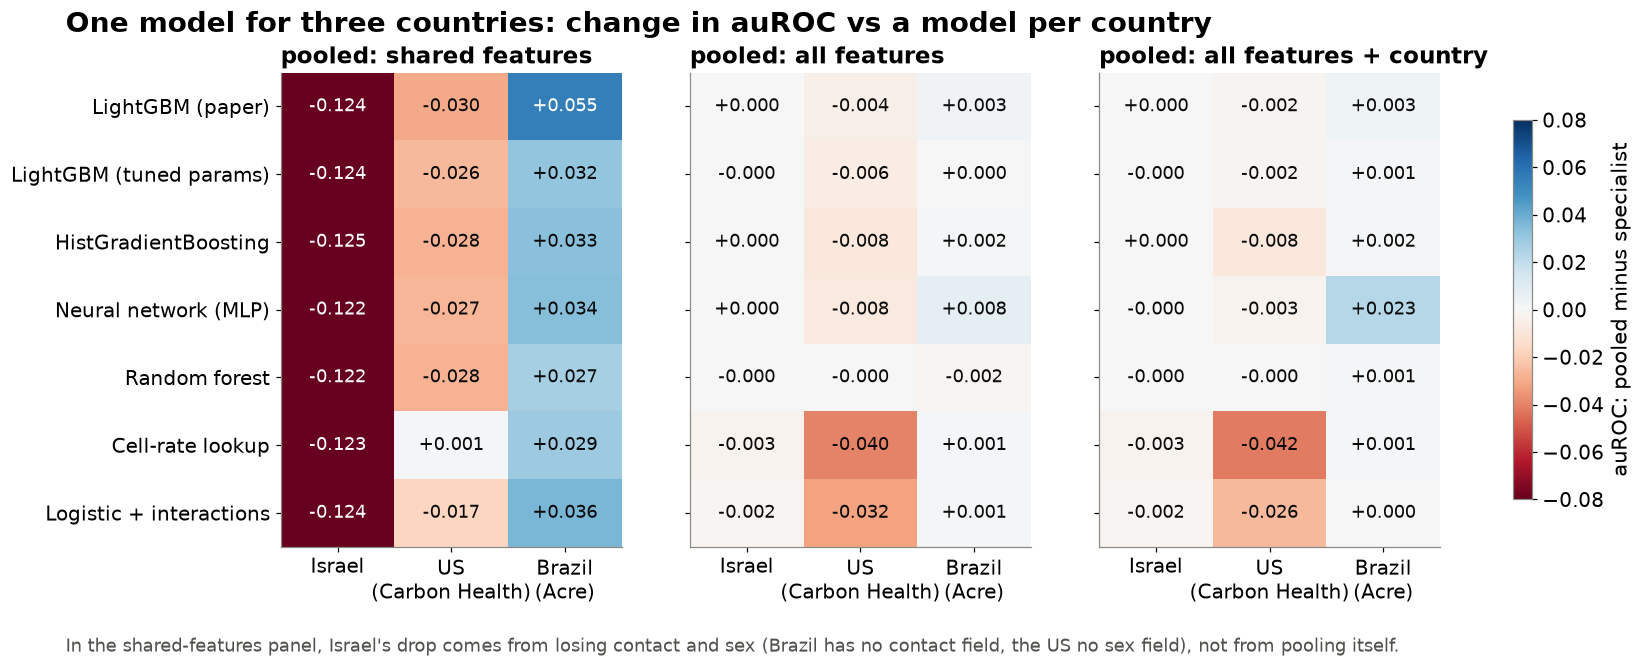

In [33]:
with plt.rc_context(SLIDE_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), sharey=True)
    for ax, v in zip(axes, VARIANTS):
        d = pool_delta[v]
        im = ax.imshow(d.values, cmap="RdBu", vmin=-0.08, vmax=0.08, aspect="auto")
        for i in range(d.shape[0]):
            for j in range(d.shape[1]):
                ax.text(j, i, f"{d.iloc[i, j]:+.3f}", ha="center", va="center", fontsize=12,
                        color="white" if abs(d.iloc[i, j]) > 0.05 else "#0b0b0b")
        ax.set_xticks(range(d.shape[1]), [DISPLAY[c].replace(" (", "\n(") for c in d.columns])
        ax.set_yticks(range(d.shape[0]), d.index)
        ax.set_title(v.replace("pooled, ", "pooled: "), loc="left", fontsize=15)
        ax.grid(False)
    fig.colorbar(im, ax=axes, shrink=0.8, label="auROC: pooled minus specialist")
    fig.text(0.01, -0.06, "In the shared-features panel, Israel's drop comes from losing contact and sex (Brazil has no contact field, "
             "the US no sex field), not from pooling itself.", fontsize=12, color="#52514e")
    fig.suptitle("One model for three countries: change in auROC vs a model per country", fontweight="bold",
                 fontsize=18, x=0.01, ha="left")
    save(fig, "4_pooling_by_technique")
    plt.show()

### Asset 5: a country the model has never seen

saved assets/alternative-modelling/5_unseen_country.png


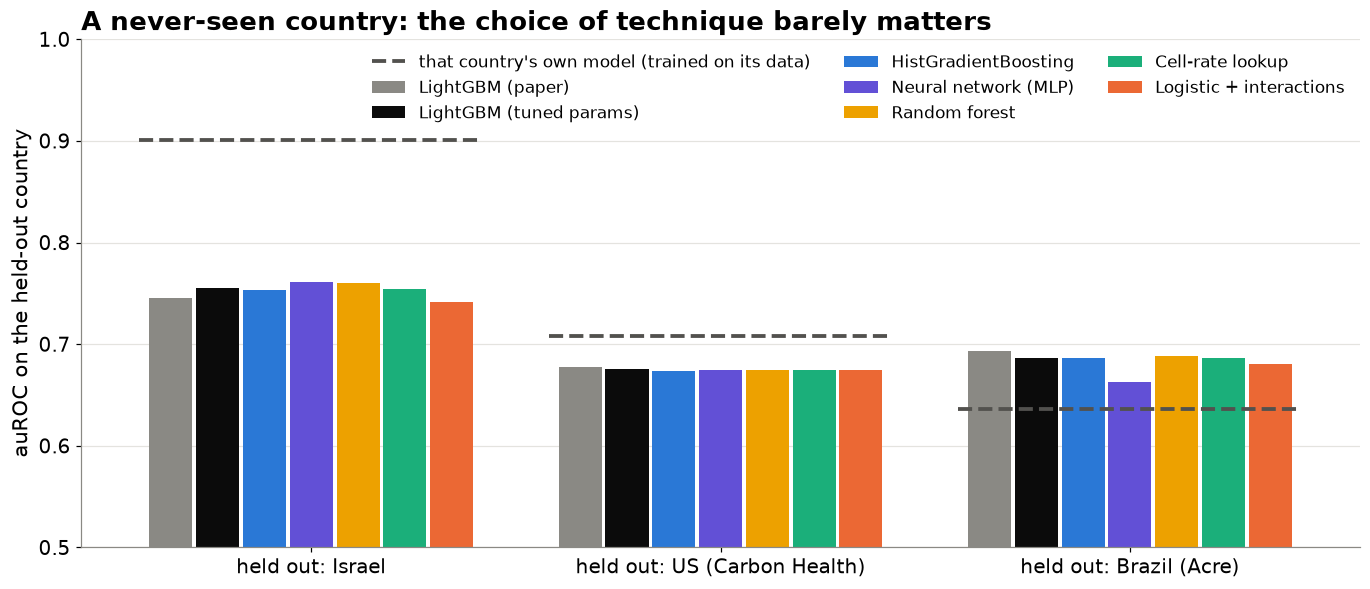

In [34]:
with plt.rc_context(SLIDE_STYLE):
    fig, ax = plt.subplots(figsize=(15, 6))
    handles, labels = loo_chart(ax, big=True)
    ax.set_xticks(range(len(SPLITS)), [f"held out: {DISPLAY[n]}" for n in SPLITS])
    labels = [l.replace("that country's own LightGBM", "that country's own model (trained on its data)") for l in labels]
    ax.legend(handles, labels, frameon=False, ncol=3, loc="upper right", fontsize=11)
    ax.set_ylim(0.5, 1.0)
    ax.set_title("A never-seen country: the choice of technique barely matters", loc="left")
    save(fig, "5_unseen_country")
    plt.show()

### Suggested slides

| Slide | Asset | Message |
|---|---|---|
| "Is there room to improve?" | `1_headroom.png` | The tuned model is already within 0.001 auROC of the best any model could do with these 8 answers |
| "Fifteen techniques" | `2_leaderboard.png` | Anything that can model interactions reaches the ceiling with default settings; simple additive models fall short |
| "Is it the bias?" | `3_bias_check.png` | No: with or without the biased symptoms and contact, the paper's model is furthest from the ceiling and the alternatives close the gap |
| "One model for three countries?" | `4_pooling_by_technique.png` | Pooling's effect is the same whichever technique is used: neutral with all features, helpful for Brazil with shared ones |
| "A country it's never seen" | `5_unseen_country.png` | Technique barely matters; local data matters more (except in Brazil, where older local data is a poor guide) |

### Takeaways
1. **Several techniques beat the paper's LightGBM, robustly, but none beats the tuned model.** The tuned model sits at the ceiling of what 8 yes/no answers allow.
2. **The paper's model was handicapped, not outclassed.** One hyperparameter (`feature_fraction=0.2`) stopped it learning combinations of answers. Any technique that can learn them, including a transparent logistic regression with pairwise interactions, does as well as the tuned model.
3. **More modelling effort won't help on this data.** Ensembles, tuning the alternatives, recency weighting and extra training data from other countries all land on the same ceiling.
4. **Across countries, technique choice is second-order.** The best technique differs by country, and the gaps are small. In the US the paper's original, heavily regularised settings win.
5. **For generalising to new countries, the features matter more than the model.** Use features every country collects. Don't add country indicators, which backfire on an unseen country. Pooling helps where a country's own past data is a poor guide to its present (Brazil 2022).
6. **The real lever is better data:** more informative questions and unbiased recording. Removing contact or the biased symptoms moves the ceiling by 0.03–0.15. Changing technique moves results by about 0.001.